# 3. Calibrate the fitted vectors

Run **02_fitting.ipynb** first. This notebook reads fitted vectors and applies the original calibration function as an independent post-processing step.

The affine transform maps lattice 1 to a reference basis, then applies the same transform to lattice 2. It returns corrected vectors and twist angles; it does not resample the diffraction image or modify the fit.

Reference values are real-space **d spacings**. For sampling in `1/nm` per pixel, enter d spacings in `nm`. The original algorithm uses `sampling[0]`, including when two sampling values are stored.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Locate this checkout when launched from the project or an examples directory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/moire_cdw").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from moire_cdw.results import load_fit_result
from moire_cdw.calibration import calibration_from_vectors

## Reference settings

The values below reproduce the old calibration example (`0.276 nm`, `60 degrees`); they are not independently established for another material or reflection. Change them to the reference appropriate for your selected lattice 1.

In [2]:
FIT_FILE = ROOT / "outputs/two_lattice/fit.npz"
OUTPUT = ROOT / "outputs/two_lattice/calibration.npz"
D_U1 = 0.276
D_V1 = 0.276
REFERENCE_ANGLE_DEG = 60.0

## Read the fitting result

In [3]:
if not FIT_FILE.exists():
    raise FileNotFoundError("Run 02_fitting.ipynb first.")
result = load_fit_result(FIT_FILE)
summary = result["summary"]
vectors = {key: summary[key] for key in ("origin_rc", "u1_rc", "v1_rc", "u2_rc", "v2_rc")}
print("Input:", result["metadata"]["source_file"])
print("Sampling:", result["sampling"], "Units:", result["units"])
print("Fit settings:", result["metadata"]["fit_settings"])
if result["units"] != ["1/nm", "1/nm"]:
    raise ValueError("This example assumes d spacings in nm and sampling in 1/nm. Check units before calibration.")

Input: /Users/hu/Project/Moire/Morie/Moire_CDW/data/Bi_1_total_0010.dm4
Sampling: [0.01444064 0.01444064] Units: ['1/nm', '1/nm']
Fit settings: {'model': 'parent', 'quick_run': True, 'device': 'cpu', 'loss_mode': 'log1p', 'build': {'center_radius_px': 9, 'spot_radius_px': 5, 'origin_delta_px': 6.0, 'uv_delta_px': 4.0, 'lattice_order': 6, 'center_intensity': 1.0, 'spot_intensity': 0.12, 'gaussian_bg_sigma': 70.0, 'gaussian_bg_intensity': 0.03, 'dc_bg_intensity': 0.005, 'refine_center_template': False, 'refine_spot_templates': True, 'tv_weight': 0.0001, 'boundary_px': 7.0}, 'stages': {'lr1': 0.2, 'lr2': 0.05, 'lr3': 0.02, 'constraint_weight': 1.0, 'stage1_steps': 3, 'stage2_steps': 3, 'stage3_steps': 3}, 'center_mask': {'radius_px': 12, 'center_weight': 0.2}, 'detection': {'source_file': '/Users/hu/Project/Moire/Morie/Moire_CDW/data/Bi_1_total_0010.dm4', 'bin_factor': 4, 'random_seed': 0, 'peak_settings': {'refine_radius_px': 3, 'sigma': 4.0, 'threshold': 16000.0, 'min_distance_px': 20},

## Apply calibration to the fitted vectors

60.01526195872482 59.91106715571625 [18.86098326107622, 138.7873123755173, 78.77205041679247, 78.87624521980104]


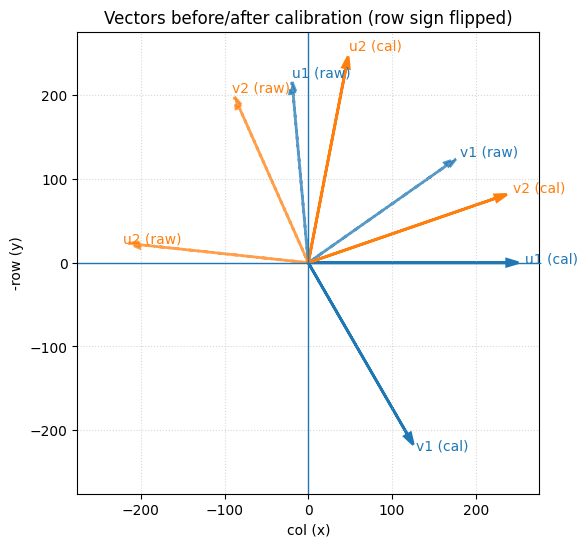

59.999999999999986 60.06568794313232 [18.996904573066647, 139.06259251619895, 79.06259251619895, 78.99690457306663]
[Calibration] angle_vector1(before) = 60.015°
[Calibration] angle1_calibrate candidates = 60.000° or 120.000° -> chosen 60.000°
[Calibration] |u1_ref|=250.902px, |v1_ref|=250.902px
[Calibration] A=
[[-0.10397058  1.15934077]
 [-1.15241679 -0.09866498]]
[Calibration] angle(u1_cal, v1_cal) = 60.000° (target 60.000°)
[Calibration] angle(u2_cal, v2_cal) = 60.066° (target 60.000°)
[Twist] before calibration = 18.861°
[Twist] after  calibration = 18.997°
[Ratio] before calibration |u1|/|u2| = 1.005,  |v1|/|v2| = 0.993
[Ratio] after calibration |u1|/|u2| = 1.000,  |v1|/|v2| = 1.001
Twist before calibration: 18.860983261076214
Twist after calibration: 18.996904573066644


In [4]:
info = calibration_from_vectors(
    **vectors, sampling=result["sampling"], u1_calibrate=D_U1, v1_calibrate=D_V1,
    angle1_calibrate=REFERENCE_ANGLE_DEG, return_info=True, plot_vectors=True,
)
print("Twist before calibration:", info["twist_angle_before"])
print("Twist after calibration:", info["twist_angle_after"])

## Save calibration separately

The fitting result remains available unchanged. `A` operates on `(row, col)` vectors in binned pixels. Corrected reciprocal lengths are obtained by multiplying their norms by the original first sampling value.

In [5]:
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUTPUT, **info, **vectors, sampling=result["sampling"],
                    units=np.asarray(result["units"]), source_fit=str(FIT_FILE),
                    d_u1=D_U1, d_v1=D_V1, reference_angle_deg=REFERENCE_ANGLE_DEG)
print("Saved:", OUTPUT)

Saved: /Users/hu/Project/Moire/Morie/Moire_CDW/outputs/two_lattice/calibration.npz


For the original peak-index interface, use `from moire_cdw.calibration import calibration`, then call `calibration(peaks, vector_indices, im_bin, ...)`. Its defaults and return behavior are unchanged.